# 04 — Seasonal availability

**Does:** re-runs the Part 1 dispatch model with solar, wind and hydro availability varying by month, and compares it with the constant-availability baseline from notebook 03.

**Question:** how much do prices, the generation mix and inter-state trade change when renewable output follows the seasons?

**Input:** `data/raw/seasonal_availability.csv` plus the Part 1 inputs; baseline results `data/processed/dispatch_*_daily.csv` (notebook 03)

**Output:** `data/processed/seasonal_state_daily.csv`, `seasonal_flows_daily.csv`, `seasonal_national_daily.csv`

**Logged in:** `docs/model_log.md`, step 10

## Design

| Choice | Value | Why |
|---|---|---|
| Fuels that vary | Solar, Wind, Large Hydro, Small Hydro | Driven by weather and rainfall |
| Granularity | One factor per month | Daily data has no time of day; monthly captures the seasons |
| **Annual average** | **Equal to the constant factors** (0.25, 0.30, 0.45, 0.40) | Same yearly renewable supply as the baseline, so any difference comes from *timing* alone |
| Coal, lignite, nuclear, gas, biopower, diesel | Constant all year (as in Part 1) | Kept constant on purpose to isolate the renewable effect. In reality coal availability also dips in the monsoon (wet coal, planned maintenance); not modelled |
| Everything else | Unchanged from Part 1 | Coal tiers, losses, VOLL, demand |

**Limitation:** solar availability *at the daily peak* also depends on *when* the peak happens (afternoon in summer, evening in winter and the monsoon). Monthly factors don't capture time of day.

In [1]:
import sys
sys.path.append("../src")

import calendar
import time
import pandas as pd
import matplotlib.pyplot as plt

from dispatch import (AVAILABILITY, load_generators, load_demand, load_coordinates, loss_matrix,
                      load_seasonal_availability, LossDispatchModel, run_all_days, PROCESSED)

MONTHS = [calendar.month_abbr[m] for m in range(1, 13)]

## Step 1: the seasonal factors

12-month average vs constant factor:
             seasonal avg  constant
Solar                0.25      0.25
Wind                 0.30      0.30
Large Hydro          0.45      0.45
Small Hydro          0.40      0.40


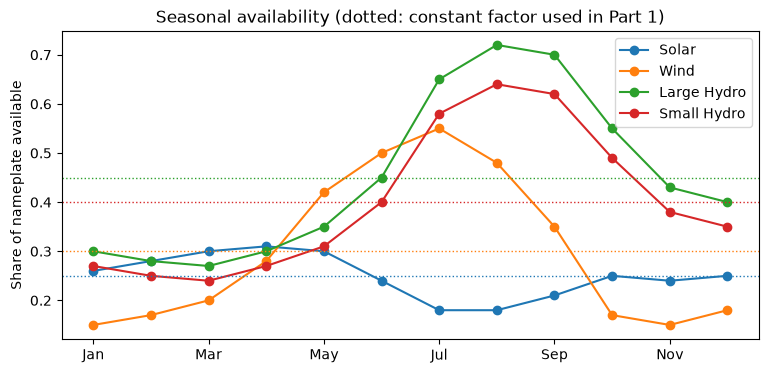

In [2]:
seasonal = load_seasonal_availability()
print("12-month average vs constant factor:")
print(pd.DataFrame({"seasonal avg": seasonal.mean().round(3),
                    "constant": pd.Series(AVAILABILITY)[seasonal.columns]}))

ax = seasonal.set_axis(MONTHS).plot(marker="o", figsize=(9, 4))
for fuel, color in zip(seasonal.columns, plt.rcParams["axes.prop_cycle"].by_key()["color"]):
    ax.axhline(AVAILABILITY[fuel], color=color, linestyle=":", linewidth=1)
ax.set_ylabel("Share of nameplate available")
ax.set_title("Seasonal availability (dotted: constant factor used in Part 1)")
plt.show()

## Step 2: run both models

In [3]:
gen = load_generators()
demand = load_demand()
states = list(demand.columns)
loss = loss_matrix(load_coordinates(), states)
model = LossDispatchModel(gen, loss, states)

t0 = time.time()
s_state, s_flows, s_nat = run_all_days(model, demand, seasonal=seasonal)
print(f"Seasonal run: {len(s_nat)} days in {time.time() - t0:.1f} s")

# Baseline: constant availability, from notebook 03
b_state = pd.read_csv(PROCESSED / "dispatch_state_daily.csv", parse_dates=["Date"])
b_nat = pd.read_csv(PROCESSED / "dispatch_national_daily.csv", parse_dates=["Date"])

Seasonal run: 1917 days in 9.2 s


## Step 3: validation

In [4]:
fuel_cols = [c for c in s_nat.columns if c.endswith("_MW") and c not in
             ("Demand_MW", "Unserved_MW", "Traded_MW", "Losses_MW")]

# 1. Energy balance every day
extra = s_nat[fuel_cols].sum(axis=1) - s_nat["Demand_MW"] + s_nat["Unserved_MW"]
print("1. Largest energy-balance error (MW):", (extra - s_nat["Losses_MW"]).abs().max())

# 2. Same demand as the baseline
print("2. Demand identical to baseline:", (s_nat["Demand_MW"].values == b_nat["Demand_MW"].values).all())

# 3. A day's available capacity really follows its month
jul = model.solve(demand.loc["2024-07-21"], {**AVAILABILITY, **seasonal.loc[7].to_dict()})["generation"]
hydro = jul[jul["Fuel_Type"] == "Large Hydro"]
print("3. July large-hydro availability / nameplate:",
      round(hydro["Available_MW"].sum() / hydro["Capacity_MW"].sum(), 3), "(expect 0.65)")

# 4. Sanity
print("4. Negative prices:", (s_state["Price"] < 0).sum(),
      "| days with unserved demand:", (s_nat["Unserved_MW"] > 1e-6).sum())
print(f"5. Losses / traded power: {100 * s_nat['Losses_MW'].sum() / s_nat['Traded_MW'].sum():.2f}%")

1. Largest energy-balance error (MW): 4.8203219193965197e-11
2. Demand identical to baseline: True
3. July large-hydro availability / nameplate: 0.65 (expect 0.65)
4. Negative prices: 0 | days with unserved demand: 0
5. Losses / traded power: 3.81%


## Step 4: prices over time

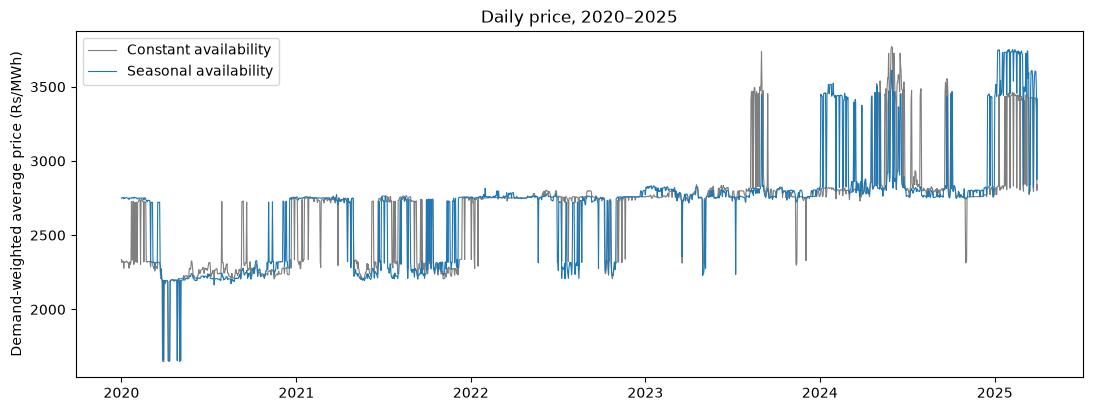

,Constant,Seasonal
count,1917.0,1917.0
mean,2677.0,2701.0
std,324.0,356.0
min,1648.0,1650.0
25%,2323.0,2321.0
50%,2753.0,2754.0
75%,2796.0,2798.0
max,3770.0,3751.0


In [5]:
b = b_nat.set_index("Date")
s = s_nat.set_index("Date")

fig, ax = plt.subplots(figsize=(13, 4.5))
ax.plot(b.index, b["Price_avg"], color="tab:gray", linewidth=0.8, label="Constant availability")
ax.plot(s.index, s["Price_avg"], color="tab:blue", linewidth=0.8, label="Seasonal availability")
ax.set_ylabel("Demand-weighted average price (Rs/MWh)")
ax.set_title("Daily price, 2020–2025")
ax.legend(loc="upper left")
plt.show()

summary = pd.DataFrame({"Constant": b["Price_avg"].describe(), "Seasonal": s["Price_avg"].describe()}).round(0)
summary

## Step 5: the seasonal pattern

Averages use full years 2020–2024 only: the data runs to March 2025, so including it would give Jan–Mar one extra (higher-demand) year.

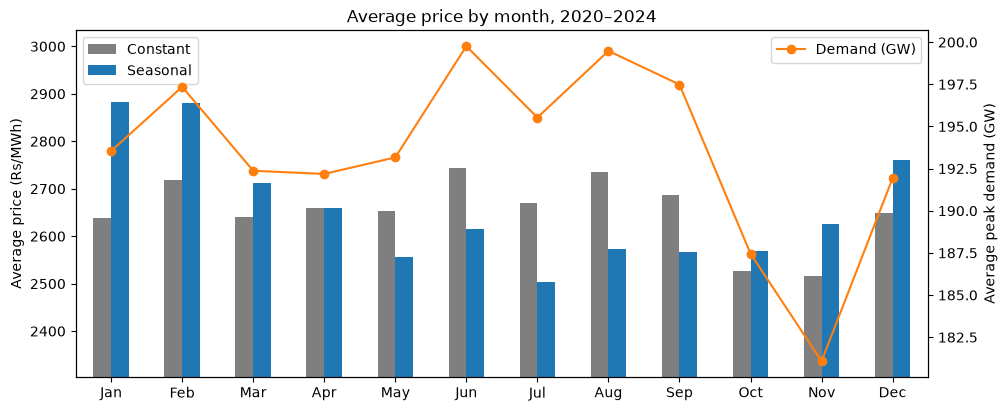

,Constant,Seasonal,Demand_GW,Change
Jan,2638.0,2883.0,194.0,245.0
Feb,2718.0,2881.0,197.0,164.0
Mar,2641.0,2713.0,192.0,72.0
Apr,2660.0,2660.0,192.0,-0.0
May,2652.0,2557.0,193.0,-95.0
Jun,2745.0,2616.0,200.0,-129.0
Jul,2671.0,2503.0,196.0,-167.0
Aug,2736.0,2574.0,199.0,-162.0
Sep,2686.0,2567.0,197.0,-119.0
Oct,2527.0,2568.0,187.0,41.0


In [6]:
full = slice("2020-01-01", "2024-12-31")
by_month = pd.DataFrame({
    "Constant": b.loc[full, "Price_avg"].groupby(b.loc[full].index.month).mean(),
    "Seasonal": s.loc[full, "Price_avg"].groupby(s.loc[full].index.month).mean(),
    "Demand_GW": b.loc[full, "Demand_MW"].groupby(b.loc[full].index.month).mean() / 1000,
}).set_axis(MONTHS)
by_month["Change"] = by_month["Seasonal"] - by_month["Constant"]

fig, ax = plt.subplots(figsize=(11, 4.5))
by_month[["Constant", "Seasonal"]].plot(kind="bar", ax=ax, color=["tab:gray", "tab:blue"], rot=0)
ax.set_ylim(by_month[["Constant", "Seasonal"]].min().min() - 200, by_month[["Constant", "Seasonal"]].max().max() + 150)
ax.set_ylabel("Average price (Rs/MWh)")
ax.set_title("Average price by month, 2020–2024")
ax.legend(loc="upper left")
ax2 = ax.twinx()
ax2.plot(range(12), by_month["Demand_GW"], color="tab:orange", marker="o", label="Demand (GW)")
ax2.set_ylabel("Average peak demand (GW)")
ax2.legend(loc="upper right")
plt.show()

by_month.round(0)

## Step 6: generation mix by month

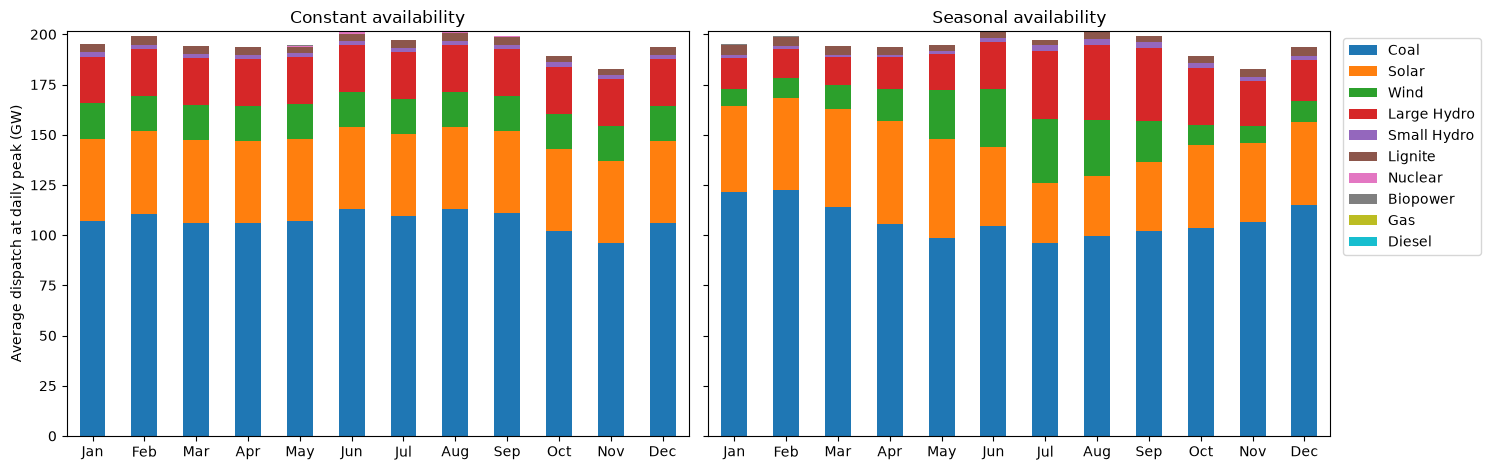

Change in average dispatch (GW), seasonal minus constant:


,Coal,Solar,Wind,Large Hydro,Small Hydro,Lignite,Nuclear
Jan,14.4,1.6,-8.7,-7.8,-0.7,0.2,0.5
Feb,11.6,4.9,-7.6,-8.8,-0.8,0.0,0.2
Mar,7.6,8.2,-5.8,-9.3,-0.8,0.1,0.0
Apr,-0.2,9.9,-1.2,-7.8,-0.7,-0.0,-0.0
May,-8.4,8.2,7.0,-5.2,-0.5,-0.5,-0.3
Jun,-8.5,-1.6,11.6,0.0,0.0,-0.5,-0.6
Jul,-13.1,-11.5,14.5,10.4,0.9,-1.2,-0.1
Aug,-13.3,-11.5,10.5,14.0,1.2,-0.4,-0.3
Sep,-9.0,-6.6,2.9,13.0,1.1,-1.1,-0.3
Oct,1.6,0.0,-7.6,5.2,0.5,0.3,0.0


In [7]:
def mix_by_month(nat):
    n = nat.set_index("Date").loc[full]
    m = n[fuel_cols].groupby(n.index.month).mean() / 1000
    m.columns = [c.replace("_MW", "") for c in m.columns]
    return m.set_axis(MONTHS)

b_mix, s_mix = mix_by_month(b_nat), mix_by_month(s_nat)
order = ["Coal", "Solar", "Wind", "Large Hydro", "Small Hydro", "Lignite", "Nuclear", "Biopower", "Gas", "Diesel"]
order = [f for f in order if f in b_mix.columns]

fig, ax = plt.subplots(1, 2, figsize=(15, 4.8), sharey=True)
b_mix[order].plot(kind="bar", stacked=True, ax=ax[0], rot=0, legend=False, title="Constant availability")
s_mix[order].plot(kind="bar", stacked=True, ax=ax[1], rot=0, title="Seasonal availability")
ax[0].set_ylabel("Average dispatch at daily peak (GW)")
ax[1].legend(bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.show()

change = (s_mix - b_mix)[["Coal", "Solar", "Wind", "Large Hydro", "Small Hydro", "Lignite", "Nuclear"]]
print("Change in average dispatch (GW), seasonal minus constant:")
change.round(1)

## Step 7: which states change most

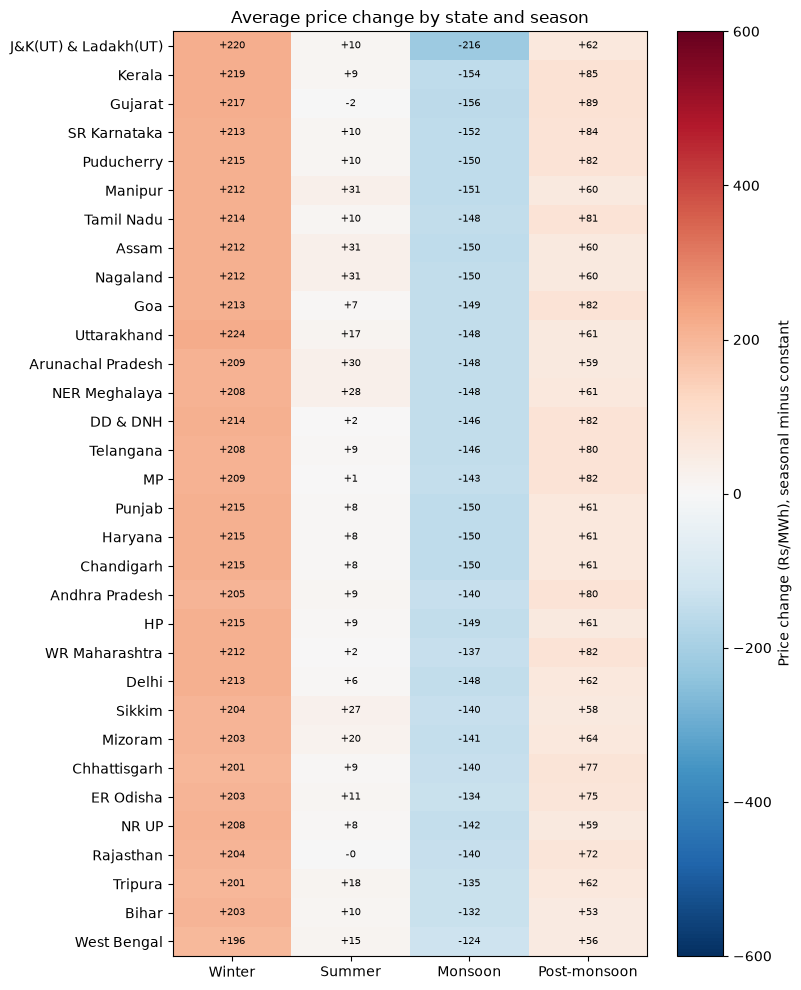

In [8]:
bs = b_state.assign(Season=b_state["Date"].dt.month)
ss = s_state.assign(Season=s_state["Date"].dt.month)
season_of = {12: "Winter", 1: "Winter", 2: "Winter", 3: "Summer", 4: "Summer", 5: "Summer",
             6: "Monsoon", 7: "Monsoon", 8: "Monsoon", 9: "Monsoon", 10: "Post-monsoon", 11: "Post-monsoon"}
bs["Season"] = bs["Season"].map(season_of)
ss["Season"] = ss["Season"].map(season_of)
seasons = ["Winter", "Summer", "Monsoon", "Post-monsoon"]

price_change = (ss.groupby(["State", "Season"])["Price"].mean()
                - bs.groupby(["State", "Season"])["Price"].mean()).unstack()[seasons]
price_change = price_change.loc[price_change.abs().mean(axis=1).sort_values(ascending=False).index]

fig, ax = plt.subplots(figsize=(8, 10))
im = ax.imshow(price_change, cmap="RdBu_r", vmin=-600, vmax=600, aspect="auto")
ax.set_xticks(range(4), seasons)
ax.set_yticks(range(len(price_change)), price_change.index)
for i in range(len(price_change)):
    for j in range(4):
        ax.text(j, i, f"{price_change.iloc[i, j]:+.0f}", ha="center", va="center", fontsize=7)
plt.colorbar(im, label="Price change (Rs/MWh), seasonal minus constant")
ax.set_title("Average price change by state and season")
plt.tight_layout()
plt.show()

In [9]:
# Net exports of the main hydro states by season (GW, + = export)
hydro_states = ["HP", "Sikkim", "Arunachal Pradesh", "J&K(UT) & Ladakh(UT)", "Uttarakhand"]

def net_export(df):
    d = df[df["State"].isin(hydro_states)]
    return ((d["Exports_sent_MW"] - d["Imports_received_MW"]) / 1000).groupby([d["State"], d["Season"]]).mean().unstack()[seasons]

pd.concat({"Constant": net_export(bs), "Seasonal": net_export(ss)}, axis=1).round(2)

Constant                             Seasonal         \
Season                 Winter Summer Monsoon Post-monsoon   Winter Summer   
State                                                                       
Arunachal Pradesh        0.86   0.88    0.87         0.88     0.58   0.55   
HP                       3.81   4.19    4.16         4.03     2.24   2.40   
J&K(UT) & Ladakh(UT)    -1.11  -0.81   -0.69        -0.86    -1.57  -1.33   
Sikkim                   0.93   0.95    0.96         0.96     0.64   0.61   
Uttarakhand              0.37   0.71    0.50         0.66    -0.27  -0.01   

                                           
Season               Monsoon Post-monsoon  
State                                      
Arunachal Pradesh       1.28         0.97  
HP                      6.40         4.54  
J&K(UT) & Ladakh(UT)   -0.04        -0.71  
Sikkim                  1.39         1.06  
Uttarakhand             1.40         0.88

## Step 8: cost over a year

In [10]:
yearly = pd.DataFrame({
    "Constant": b.loc[full, "Total_cost_Rs_per_h"].groupby(b.loc[full].index.year).mean() / 1e7,
    "Seasonal": s.loc[full, "Total_cost_Rs_per_h"].groupby(s.loc[full].index.year).mean() / 1e7,
})
yearly["Change_%"] = 100 * (yearly["Seasonal"] / yearly["Constant"] - 1)
print("Average system cost at the daily peak (Rs crore per hour):")
yearly.round(2)

Average system cost at the daily peak (Rs crore per hour):


,Constant,Seasonal,Change_%
Date,,,
2020,17.82,17.95,0.73
2021,21.40,21.47,0.34
2022,25.24,25.25,0.02
2023,29.01,28.98,-0.10
2024,32.04,32.01,-0.08


## Conclusions

**1. The seasonal price pattern flips.** With constant availability, prices simply follow demand (highest in Jun and Aug). With seasonal availability the timing of renewables dominates:

| Season | Price change | Why |
|---|---|---|
| **Monsoon (Jun–Sep)** | **−120 to −170 Rs/MWh** | Wind (up to 0.55) and hydro (up to 0.72) push 9–13 GW of coal off the system |
| **Winter (Dec–Feb)** | **+110 to +245 Rs/MWh** | Weak wind and low hydro: 9–14 GW more coal, more expensive tiers at the margin |
| Summer (Mar–May) | −95 to +72 Rs/MWh | Low hydro is offset by strong solar and May's rising wind |
| Post-monsoon (Oct–Nov) | +40 to +110 Rs/MWh | Wind drops away before hydro does |

**2. The hypothesis "summer prices rise" was wrong.** Strong summer solar (0.30–0.31) and May wind make up for low reservoirs. Winter, not summer, is the expensive season in this model.

**3. Every state moves the same way.** Price changes are similar across states (winter about +200, monsoon about −150), because prices are linked through trade. J&K, Kerala and Gujarat change most.

**4. Hydro states become seasonal exporters.** HP exports 6.4 GW in the monsoon but 2.2 GW in winter (constant model: ~4 GW all year). Sikkim and Arunachal double their monsoon exports; Uttarakhand turns from exporter to importer outside the monsoon.

**5. Yearly cost barely changes** (−0.1% to +0.7%), as designed: the same yearly renewable supply, timed differently. Price variation grows (standard deviation 324 → 356 Rs/MWh).

**Caveats:** coal availability is constant (in reality it dips in the monsoon, which would soften the monsoon price fall); monthly factors ignore the time of day of the peak (winter and monsoon peaks are in the evening, when solar is weaker, so winter prices may be understated); the factor shapes are assumptions, not measured data.

## Step 9: save

In [11]:
s_state.to_csv(PROCESSED / "seasonal_state_daily.csv", index=False)
s_flows.to_csv(PROCESSED / "seasonal_flows_daily.csv", index=False)
s_nat.to_csv(PROCESSED / "seasonal_national_daily.csv", index=False)

for name, df in [("state", s_state), ("flows", s_flows), ("national", s_nat)]:
    print(f"seasonal_{name}_daily.csv: {len(df):,} rows")

seasonal_state_daily.csv: 61,344 rows
seasonal_flows_daily.csv: 57,390 rows
seasonal_national_daily.csv: 1,917 rows
